# Validate the RL code

Salazar's RL code (`core/rl/`, copied from the original repository, isolated from
the market) trained on small test environments with a known best return
(`core/envs/toy.py`). No market: if a paradigm does not learn here, the problem
is in the RL code, not in the market.

1. **Environments**: the tasks and their baseline returns
2. **Interface**: what each training paradigm sees (per agent or grouped)
3. **Training**: each paradigm on the individual-reward task
4. **What is updated**: which networks change during training
5. **Team reward**: each paradigm on the shared-reward task
6. **Full trainer**: `RLTrainer.train` with Ray Tune (off by default)

Training here uses `train_local` (`core/rl/local.py`): the trainer's own
algorithm configuration, run in this process instead of Ray Tune's worker
processes, so it fits in memory and starts in seconds. Run with the `marlem`
conda env as kernel; the whole notebook takes about 15 minutes.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT)  # Ray's worker processes import core/ too

import matplotlib.pyplot as plt
import pandas as pd

from core.envs.toy import BalanceEnv, TargetEnv, baseline_return
from core.rl.base import RLAlgorithm, TrainingMode
from core.rl.local import build_local, train_local
from core.rl.train import RLTrainer

pd.set_option("display.precision", 3)

ALGORITHM = RLAlgorithm.PPO
MODES = [TrainingMode.DTDE, TrainingMode.CTDE, TrainingMode.CTCE]
ENV_CONFIG = {"n_agents": 3, "max_steps": 10}
ITERS = 15
TRAINING = {"lr": 3e-4, "train_batch_size_per_learner": 2000}

## 1. Environments

Both tasks have 3 agents, 10 steps per episode, observations and actions in
[-1, 1]. Returns are summed over all agents, as RLlib reports them.

- **TargetEnv**: each agent sees a private 2-D target and is paid for matching
  it (individual rewards).
- **BalanceEnv**: each agent sees its own net position and chooses a trade; all
  get the same team reward for the total imbalance (credit assignment).

The best policy reaches 0 in both. A trained policy should end well above
`zero` (always act 0) and approach `best`.

In [2]:
baselines = pd.DataFrame(
    {
        env.__name__: {
            policy: baseline_return(env, ENV_CONFIG, policy)
            for policy in ("best", "zero", "random")
        }
        for env in (TargetEnv, BalanceEnv)
    }
)
baselines

,TargetEnv,BalanceEnv
best,-5.224e-15,-1.706e-15
zero,-1.015e+01,-3.364e+00
random,-1.999e+01,-6.208e+00


## 2. Interface

DTDE trains one policy per agent on the environment as it is. CTCE and CTDE
train one module on the *grouped* environment (`GroupedEnv`): all agents become
one agent `grouped_agents` with a tuple of the agents' spaces, and its reward is
the sum of the agents' rewards.

In [3]:
for mode in MODES:
    trainer = RLTrainer(TargetEnv, ENV_CONFIG, ALGORITHM, mode, iters=1, checkpoint_freq=1, cpus=1, gpus=0)
    env = trainer.env
    obs, _ = env.reset(seed=0)
    print(f"{mode.value}: {type(env).__name__}, agents {list(obs)}")
    print(f"    observation space: {env.observation_space if mode != TrainingMode.DTDE else env.observation_spaces}")

dtde: TargetEnv, agents ['agent_00', 'agent_01', 'agent_02']
    observation space: {'agent_00': Box(-1.0, 1.0, (2,), float32), 'agent_01': Box(-1.0, 1.0, (2,), float32), 'agent_02': Box(-1.0, 1.0, (2,), float32)}
ctde: GroupedTargetEnv, agents ['grouped_agents']
    observation space: Dict('grouped_agents': Tuple(Box(-1.0, 1.0, (2,), float32), Box(-1.0, 1.0, (2,), float32), Box(-1.0, 1.0, (2,), float32)))
ctce: GroupedTargetEnv, agents ['grouped_agents']
    observation space: Dict('grouped_agents': Tuple(Box(-1.0, 1.0, (2,), float32), Box(-1.0, 1.0, (2,), float32), Box(-1.0, 1.0, (2,), float32)))


## 3. Training on TargetEnv

Each paradigm trains `ITERS` iterations of `train_batch_size_per_learner`
environment steps. `TRAINING` overrides the original's settings: it starts PPO
at `lr=1e-5` and relies on population-based training to raise it, which
`train_local` does not do.

2026-10-07 12:40:09,652	INFO worker.py:2012 -- Started a local Ray instance.


C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\_private\worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
2026-10-07 12:40:11,460	WARNING algorithm_config.py:5053 -- You are running PPO on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html


C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

2026-10-07 12:40:11,840	WARNING deprecation.py:50 -- DeprecationWarning: `RLModule(config=[RLModuleConfig object])` has been deprecated. Use `RLModule(observation_space=.., action_space=.., inference_only=.., model_config=.., catalog_class=..)` instead. This will raise an error in the future!


2026-10-07 12:40:13,265	WARNING util.py:61 -- Install gputil for GPU system monitoring.


...

C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

2026-10-07 12:43:36,975	WARNING util.py:61 -- Install gputil for GPU system monitoring.


C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\gymnasium\envs\registration.py:644: UserWarning: WARN: Overriding environment rllib-single-agent-env-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")
2026-10-07 12:45:14,621	WARNING util.py:61 -- Install gputil for GPU system monitoring.


ctde: -26.35 after 15 iterations, 6.5 s/iteration


ctce: -17.27 after 15 iterations, 6.3 s/iteration


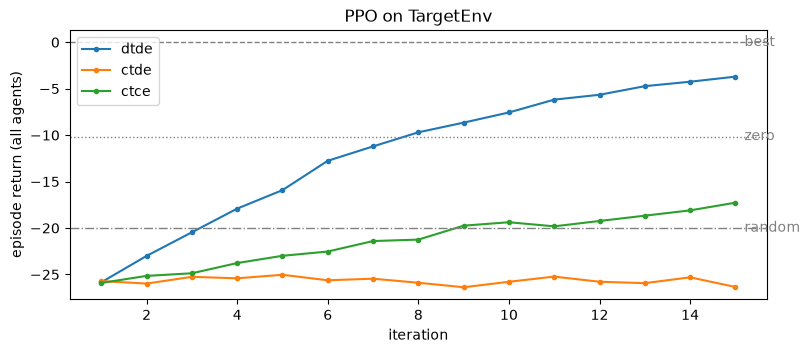

In [4]:
def compare(env_class, iters=ITERS, **training) -> pd.DataFrame:
    """Train every paradigm on ``env_class``; one column of returns per paradigm."""
    curves, seconds = {}, {}
    for mode in MODES:
        trainer = RLTrainer(env_class, ENV_CONFIG, ALGORITHM, mode, iters=1, checkpoint_freq=1, cpus=1, gpus=0)
        run = train_local(trainer, iters, **training)
        curves[mode.value] = run.return_mean
        seconds[mode.value] = run.seconds.mean()
        print(f"{mode.value}: {run.return_mean.iloc[-1]:.2f} after {iters} iterations, {seconds[mode.value]:.1f} s/iteration")
    return pd.DataFrame(curves)


def plot(curves: pd.DataFrame, env_class) -> None:
    ax = curves.plot(figsize=(9, 3.5), marker=".")
    for policy, style in (("best", "--"), ("zero", ":"), ("random", "-.")):
        ax.axhline(baselines.loc[policy, env_class.__name__], color="grey", linestyle=style, linewidth=1)
        ax.text(len(curves) + 0.2, baselines.loc[policy, env_class.__name__], policy, va="center", color="grey")
    ax.set_xlabel("iteration")
    ax.set_ylabel("episode return (all agents)")
    ax.set_title(f"{ALGORITHM.value.upper()} on {env_class.__name__}")
    plt.show()


target_curves = compare(TargetEnv, **TRAINING)
plot(target_curves, TargetEnv)

## 4. What is updated

For each paradigm: build the algorithm, train two iterations, and measure how
far each group of the learner's RL module parameters moved (for DTDE, the first
agent's module). A group that does not move
is never trained. In CTDE the agents act with their own heads (`pi_heads`,
decentralised execution), while the loss is computed from the central actor
(`pi_encoder`, `pi`).

In [5]:
def parameter_change(mode: TrainingMode, iters: int = 2) -> pd.Series:
    """Largest change of each parameter group over ``iters`` iterations."""
    trainer = RLTrainer(TargetEnv, ENV_CONFIG, ALGORITHM, mode, iters=1, checkpoint_freq=1, cpus=1, gpus=0)
    algo = build_local(trainer, **TRAINING)
    try:
        # The learner's copy: the samplers' copy leaves out what acting does not
        # need (e.g. DTDE's value function), so it would show those as unchanged.
        module_id = trainer.env.agents_id[0] if mode == TrainingMode.DTDE else "default_policy"
        modules = algo.learner_group._learner.module[module_id]
        before = {n: p.detach().clone() for n, p in modules.named_parameters()}
        for _ in range(iters):
            algo.train()
        change = {}
        for name, p in modules.named_parameters():
            group = name.split(".")[0]
            change[group] = max(change.get(group, 0.0), float((p.detach() - before[name]).abs().max()))
    finally:
        algo.stop()
    return pd.Series(change, name=mode.value)


changes = pd.concat([parameter_change(mode) for mode in MODES], axis=1)
changes

C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

2026-10-07 12:46:48,935	WARNING util.py:61 -- Install gputil for GPU system monitoring.


C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\gymnasium\envs\registration.py:644: UserWarning: WARN: Overriding environment rllib-single-agent-env-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")
2026-10-07 12:47:17,177	WARNING util.py:61 -- Install gputil for GPU system monitoring.


2026-10-07 12:47:31,390	WARNING util.py:61 -- Install gputil for GPU system monitoring.


,dtde,ctde,ctce
encoder,0.128,NaN,NaN
pi,0.049,0.114,0.098
vf,0.057,NaN,NaN
pi_encoder,NaN,0.150,0.153
vf_head,NaN,0.168,0.173
pi_heads,NaN,0.000,NaN


**Reading it.** A row with 0 in a paradigm's column is a network that training
never changes. If that network is the one the agents act with, the paradigm
cannot improve its behaviour, whatever the training curve of its loss shows.

## 5. Team reward: BalanceEnv

The same comparison with a shared reward. Every agent's reward depends on all
agents' actions, which is what centralised training is meant to help with.

C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

2026-10-07 12:47:44,951	WARNING util.py:61 -- Install gputil for GPU system monitoring.


C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\gymnasium\envs\registration.py:644: UserWarning: WARN: Overriding environment rllib-single-agent-env-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")
2026-10-07 12:51:04,277	WARNING util.py:61 -- Install gputil for GPU system monitoring.


dtde: -1.81 after 15 iterations, 13.3 s/iteration


ctde: -8.03 after 15 iterations, 6.3 s/iteration


2026-10-07 12:52:39,143	WARNING util.py:61 -- Install gputil for GPU system monitoring.


ctce: -2.05 after 15 iterations, 6.0 s/iteration


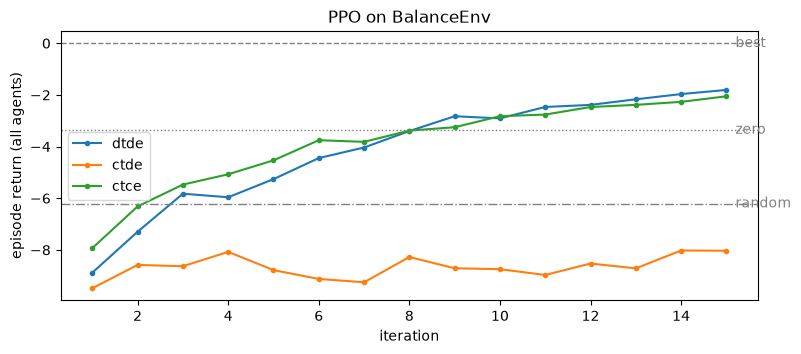

In [6]:
balance_curves = compare(BalanceEnv, **TRAINING)
plot(balance_curves, BalanceEnv)

In [7]:
summary = pd.DataFrame(
    {
        "TargetEnv: last return": target_curves.iloc[-1],
        "TargetEnv: share of the way from zero to best": 1 - target_curves.iloc[-1] / baselines.loc["zero", "TargetEnv"],
        "BalanceEnv: last return": balance_curves.iloc[-1],
        "BalanceEnv: share of the way from zero to best": 1 - balance_curves.iloc[-1] / baselines.loc["zero", "BalanceEnv"],
    }
).T
summary

,dtde,ctde,ctce
TargetEnv: last return,-3.704,-26.347,-17.273
TargetEnv: share of the way from zero to best,0.635,-1.596,-0.702
BalanceEnv: last return,-1.807,-8.032,-2.054
BalanceEnv: share of the way from zero to best,0.463,-1.388,0.389


## 6. The full trainer (Ray Tune)

`RLTrainer.train` as in the original: population-based training, separate
sampling, evaluation and learner workers, checkpoints. Each worker loads torch;
on a machine short of memory the workers fail with *"The paging file is too
small"*. Set `RUN_TUNE = True` to run it; results go to `runs/` (ignored by
git).

In [8]:
RUN_TUNE = False

if RUN_TUNE:
    trainer = RLTrainer(TargetEnv, ENV_CONFIG, ALGORITHM, TrainingMode.DTDE, iters=10, checkpoint_freq=5, cpus=1, gpus=0, storage_path=str(ROOT / "runs"))
    results, metrics = trainer.train()
    display(results[0].metrics_dataframe.filter(like="episode_return_mean"))